# 1. Preparation


## 1.1. Importing Libs and Blah Blah ...


In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import math

In [2]:
%matplotlib inline
warnings.filterwarnings('ignore')

## 1.2. Defining Init Population Function


In [3]:
def initialize_population(num_individuals, num_variables):
    pop = np.random.randint(2, size=(num_individuals, num_variables))

    return pop

In [4]:
np.random.seed(42)
pop = initialize_population(8, 5)
print(pop)

[[0 1 0 0 0]
 [1 0 0 0 1]
 [0 0 0 0 1]
 [0 1 1 1 0]
 [1 0 1 1 1]
 [1 1 1 1 1]
 [0 0 1 1 1]
 [0 1 0 0 0]]


## 1.2. Defining Benchmark Functions


In [5]:
def one_max(ind):
    value = np.sum(ind)
    return value

In [6]:
def leading_one(ind):
    value = 0
    for bit in ind:
        if not bit:
            break
        value += 1

    return value

In [7]:
def concat_trap(ind, k=5):
    value = 0
    for i in range(0, len(ind), k):
        block = ind[i : i + k]
        block_sum = np.sum(block)
        value += block_sum if block_sum == k else k - 1 - block_sum

    return value

In [8]:
print(one_max(pop[0, :]))
print(leading_one(pop[0, :]))
print(concat_trap(pop[0, :]))

1
0
3


## 1.3. Defining Selection Functions


In [9]:
def truncation_selection(pop_fitness, selection_size):
    selected_indices = np.argsort(pop_fitness)[-selection_size:]
    return selected_indices

In [10]:
def proportional_selection(pop_fitness, selection_size):
    selection_prob = pop_fitness / np.sum(pop_fitness)
    selected_indices = np.random.choice(
        len(pop_fitness), size=selection_size, p=selection_prob, replace=True
    )
    return selected_indices

In [11]:
def tournament_selection(pop_fitness, selection_size, tournament_size=4):
    pop_size = len(pop_fitness)
    assert tournament_size <= pop_size, "Tournament size cannot exceed population size."

    selected_indices = []

    tournaments_per_shuffle = pop_size // tournament_size
    num_iter = math.ceil(selection_size / tournaments_per_shuffle)

    for _ in range(num_iter):
        random_indices = np.random.permutation(pop_size)

        for i in range(0, tournaments_per_shuffle * tournament_size, tournament_size):
            tournament_indices = random_indices[i : i + tournament_size]

            winner_idx = tournament_indices[np.argmax(pop_fitness[tournament_indices])]
            selected_indices.append(winner_idx)

            # early stopping
            if len(selected_indices) == selection_size:
                return np.array(selected_indices)

    return np.array(selected_indices[:selection_size])

## 1.4. Defining Crossover


In [12]:
def crossover(pop, crossover_rate: float = 0.5):
    num_individuals = len(pop)
    num_parameters = len(pop[0])
    indices = np.arange(num_individuals)
    # Đảo ngẫu nhiên thứ tự các cá thể trong quần thể
    np.random.shuffle(indices)
    offspring = []

    for i in range(0, num_individuals, 2):
        idx1 = indices[i]
        idx2 = indices[i + 1]
        offspring1 = list(pop[idx1])
        offspring2 = list(pop[idx2])

        # Cài đặt phép lai đồng nhất uniform crossover.
        for idx in range(0, num_parameters):
            r = np.random.rand()
            if r < crossover_rate:
                temp = offspring2[idx]
                offspring2[idx] = offspring1[idx]
                offspring1[idx] = temp

        offspring.append(offspring1)
        offspring.append(offspring2)

    offspring = np.array(offspring)
    return offspring

# 2. Genetic Algorithm with POPOP Implementation


## 2.1. Defining the Main Loop of the Algorithm


In [13]:
STUDENT_ID = 23520199
N_TRIALS = 10
MAX_EVALUATIONS = 10000

### 2.1.1. GA Function


In [14]:
def genetic_algorithm(
    num_individuals,
    num_parameters,
    objective,
    selection_method,
    max_evaluations,
    verbose=False,
):
    pop = initialize_population(num_individuals, num_parameters)
    pop_fitness = np.array([objective(ind) for ind in pop])
    num_evaluations = num_individuals
    best_fitness = []
    if verbose:
        print("#Gen 0:")
        print(pop_fitness)

    selection_size = num_individuals

    while num_evaluations < max_evaluations:
        best_fitness.append([num_evaluations, np.max(pop_fitness)])

        offspring = crossover(pop)
        offspring_fitness = np.array([objective(ind) for ind in offspring])

        pop = np.vstack([pop, offspring])
        pop_fitness = np.concatenate((pop_fitness, offspring_fitness))

        num_evaluations += len(offspring)

        selected_indices = selection_method(pop_fitness, selection_size)
        pop = pop[selected_indices]
        pop_fitness = pop_fitness[selected_indices]

        if verbose:
            print(pop_fitness)

    best_fitness.append([num_evaluations, np.max(pop_fitness)])
    if verbose:
        print("#Final result:")
        print(pop)
        print(pop_fitness)

    return (pop, pop_fitness, best_fitness)

### 2.1.2. Helper Function


In [15]:
# Helper function to run the genetic algorithm and plot results, avoiding code duplication in the notebook.
def run_and_plot(
    num_individuals,
    num_parameters,
    objective_name,
    selection_method_name,
    max_evaluations,
    color="blue",
):
    fits = []
    evals = []

    if objective_name == "one_max":
        objective = one_max
    elif objective_name == "leading_one":
        objective = leading_one
    elif objective_name == "concat_trap":
        objective = concat_trap
    else:
        raise ValueError("Invalid objective function name.")

    if selection_method_name == "truncation":
        selection_method = truncation_selection
    elif selection_method_name == "proportional":
        selection_method = proportional_selection
    elif selection_method_name == "tournament":
        selection_method = tournament_selection
    else:
        raise ValueError("Invalid selection method name.")

    for i in range(N_TRIALS):

        # Set a different random seed = STUDENT_ID + 0 -> STUDENT_ID + N_TRIALS - 1
        np.random.seed(STUDENT_ID + i)

        _, _, best_fitness = genetic_algorithm(
            num_individuals,
            num_parameters,
            objective,
            selection_method,
            max_evaluations,
        )

        best_fitness = np.array(best_fitness)
        if i == 0:
            evals = best_fitness[:, 0]

        fits.append(best_fitness[:, 1])

    fits = np.array(fits)
    avg = np.mean(fits, axis=0)
    err = np.std(fits, axis=0)

    plt.figure(figsize=(12, 6))
    plt.plot(
        evals,
        avg,
        label=selection_method_name.capitalize() + f" (n={num_individuals})",
        color=color,
    )
    plt.fill_between(evals, avg - err, avg + err, alpha=0.2, color=color)
    plt.xlabel("Number of Evaluations")
    plt.ylabel("Fitness")
    plt.title(
        f"{objective_name.replace('_', ' ').title()} with {num_parameters} Dimensions"
    )
    plt.legend()
    plt.grid()
    plt.show()

    return evals, avg, err

## 2.2. Experimenting with OneMax Function (100 bits)


In [16]:
num_parameters = 100

### 2.2.1. With Truncation Selection


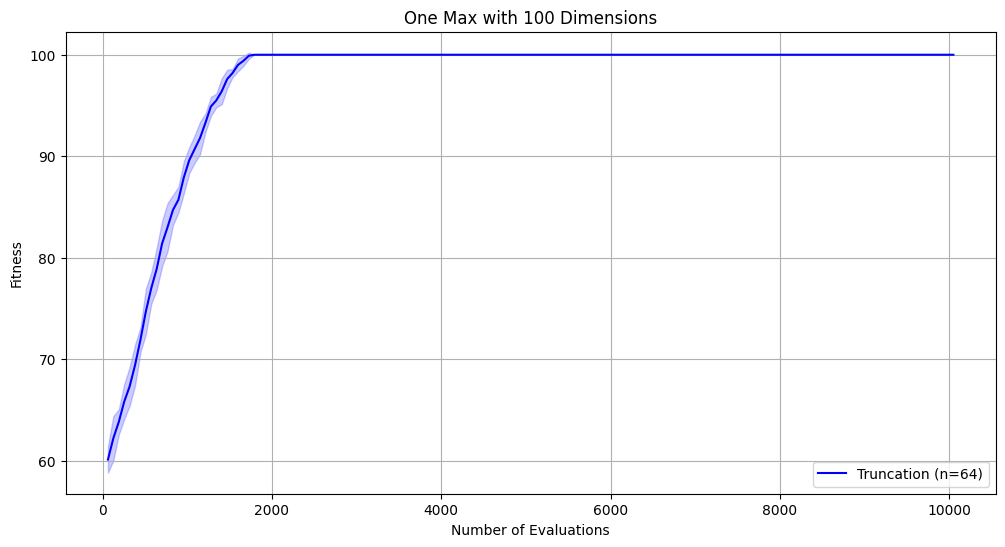

In [17]:
truncation_num_individuals = 64
truncation_evals, truncation_avg, truncation_err = run_and_plot(
    truncation_num_individuals,
    num_parameters,
    "one_max",
    "truncation",
    MAX_EVALUATIONS,
)

In [18]:
print("Max Avg Fitness:", np.max(truncation_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    truncation_evals[np.where(truncation_avg == np.max(truncation_avg))[0][0]],
)

Max Avg Fitness: 100.0
No. Evaluations to reach Max Avg Fitness: 1792


### 2.2.2. With Proportional Selection


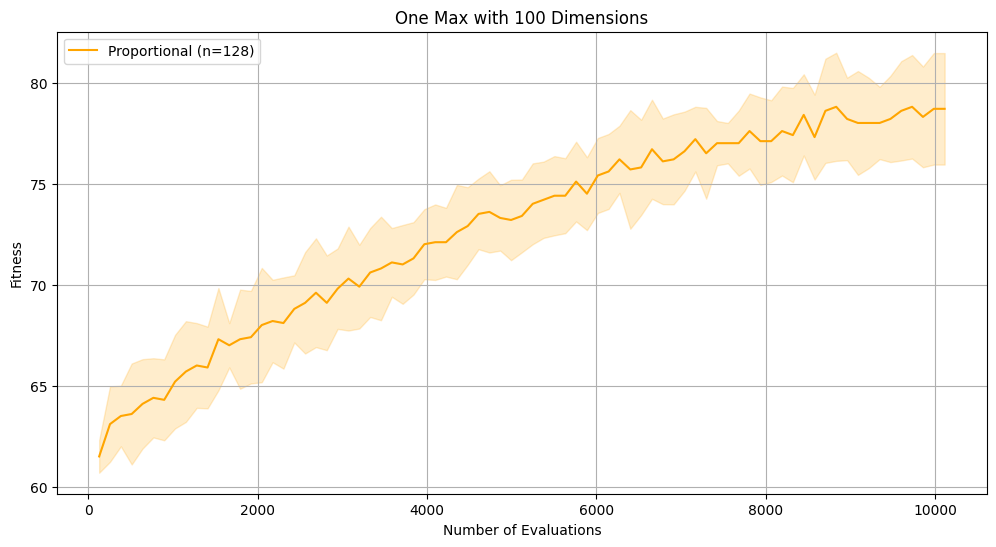

In [19]:
proportional_num_individuals = 128
proportional_evals, proportional_avg, proportional_err = run_and_plot(
    proportional_num_individuals,
    num_parameters,
    "one_max",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

In [20]:
print("Max Avg Fitness:", np.max(proportional_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    proportional_evals[np.where(proportional_avg == np.max(proportional_avg))[0][0]],
)

Max Avg Fitness: 78.8
No. Evaluations to reach Max Avg Fitness: 8832


### 2.2.3. With Tournament Selection


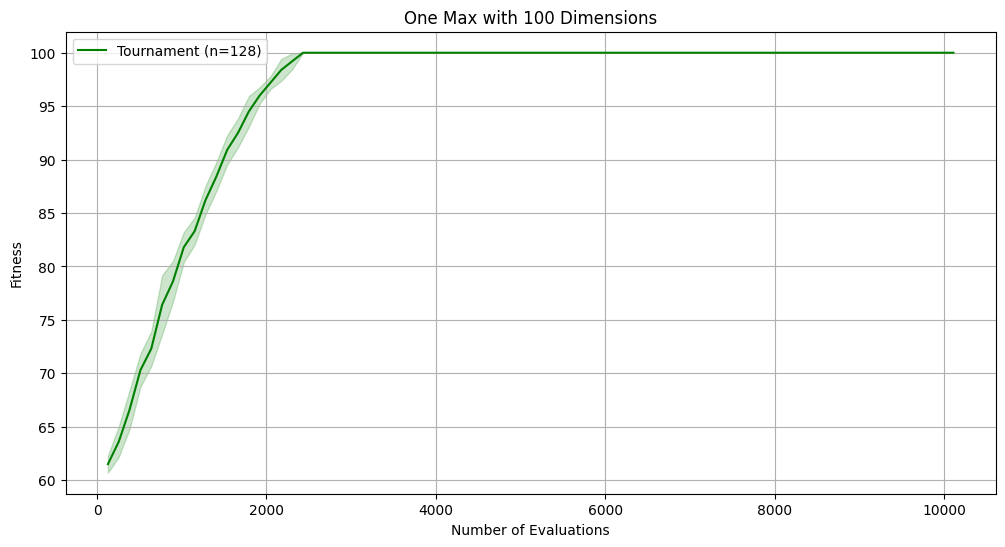

In [21]:
tournament_num_individuals = 128
tournament_evals, tournament_avg, tournament_err = run_and_plot(
    tournament_num_individuals,
    num_parameters,
    "one_max",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

In [22]:
print("Max Avg Fitness:", np.max(tournament_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    tournament_evals[np.where(tournament_avg == np.max(tournament_avg))[0][0]],
)

Max Avg Fitness: 100.0
No. Evaluations to reach Max Avg Fitness: 2432


### 2.2.4. Comparison of the Three Selection Methods


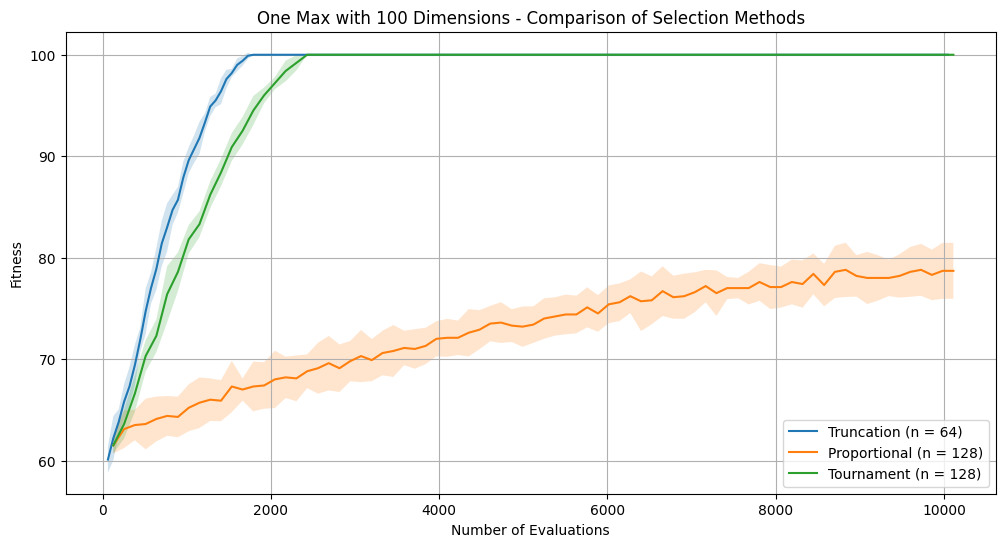

In [23]:
plt.figure(figsize=(12, 6))
plt.plot(
    truncation_evals,
    truncation_avg,
    label=f"Truncation (n = {truncation_num_individuals})",
)
plt.fill_between(
    truncation_evals,
    truncation_avg - truncation_err,
    truncation_avg + truncation_err,
    alpha=0.2,
)
plt.plot(
    proportional_evals,
    proportional_avg,
    label=f"Proportional (n = {proportional_num_individuals})",
)
plt.fill_between(
    proportional_evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(
    tournament_evals,
    tournament_avg,
    label=f"Tournament (n = {tournament_num_individuals})",
)
plt.fill_between(
    tournament_evals,
    tournament_avg - tournament_err,
    tournament_avg + tournament_err,
    alpha=0.2,
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(f"One Max with {num_parameters} Dimensions - Comparison of Selection Methods")
plt.legend()
plt.grid()
plt.show()

In [24]:
print(f"Truncation: {truncation_avg[-1]:.2f} ± {truncation_err[-1]:.2f}")
print(f"Proportional: {proportional_avg[-1]:.2f} ± {proportional_err[-1]:.2f}")
print(f"Tournament: {tournament_avg[-1]:.2f} ± {tournament_err[-1]:.2f}")

Truncation: 100.00 ± 0.00
Proportional: 78.70 ± 2.76
Tournament: 100.00 ± 0.00


### 2.2.5. Discussion


From the plot, I clearly observe that the **truncation selection** method is the overall best algorithm with One Max benchmark function.

- **Truncation Selection** achieves the highest avg fitness (100.0) with the lowest variance (0.00) in its generations after the convergence point. That indicates the method consistently finds converges to the optimal solution across all runs. The curve also shows that it converges fastest among the three methods.
- **Proportional Selection** performs the worst. It only achieves the highest avg fitness of 78.8 with a much higher variance. The curve is also much more erratic, indicating that it struggles to converge to the optimal solution.
- **Tournament Selection** performs better than proportional selection but worse than truncation selection, achieving the highest avg fitness of 100.0 and lowest variance of 0.00 after convergence but with a slower convergence rate compared to truncation selection.


## 2.3. Experimenting with LeadingOne Function (20 bits)


In [25]:
num_parameters = 20

### 2.3.1. With Truncation Selection


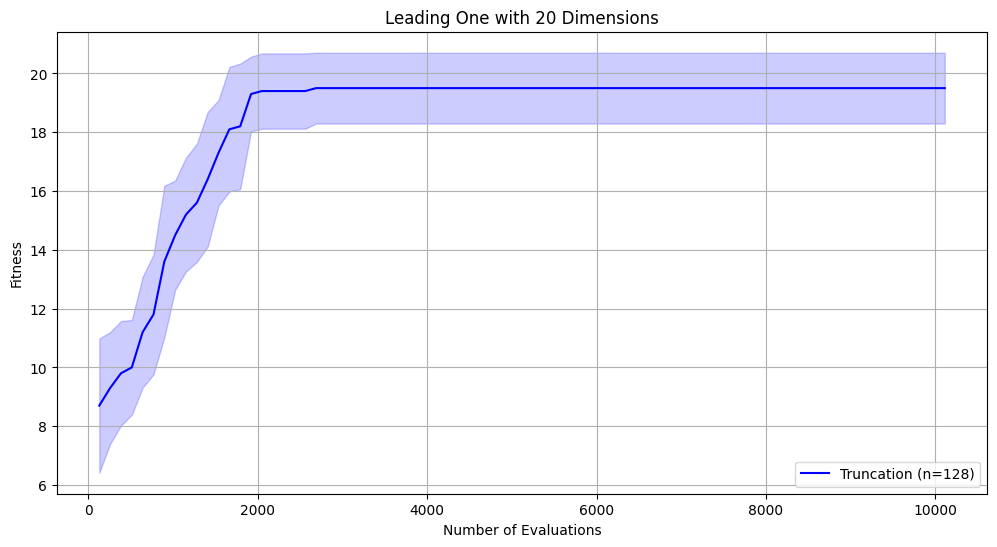

In [26]:
truncation_num_individuals = 128
truncation_evals, truncation_avg, truncation_err = run_and_plot(
    truncation_num_individuals,
    num_parameters,
    "leading_one",
    "truncation",
    MAX_EVALUATIONS,
)

In [27]:
print("Max Avg Fitness:", np.max(truncation_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    truncation_evals[np.where(truncation_avg == np.max(truncation_avg))[0][0]],
)

Max Avg Fitness: 19.5
No. Evaluations to reach Max Avg Fitness: 2688


### 2.3.2. With Proportional Selection


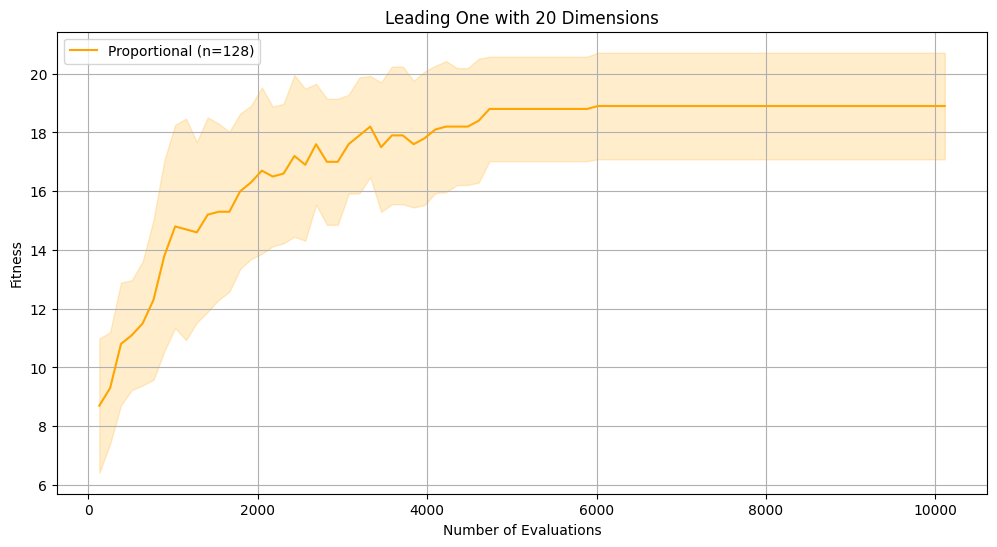

In [28]:
proportional_num_individuals = 128
proportional_evals, proportional_avg, proportional_err = run_and_plot(
    proportional_num_individuals,
    num_parameters,
    "leading_one",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

In [29]:
print("Max Avg Fitness:", np.max(proportional_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    proportional_evals[np.where(proportional_avg == np.max(proportional_avg))[0][0]],
)

Max Avg Fitness: 18.9
No. Evaluations to reach Max Avg Fitness: 6016


### 2.3.3. With Tournament Selection


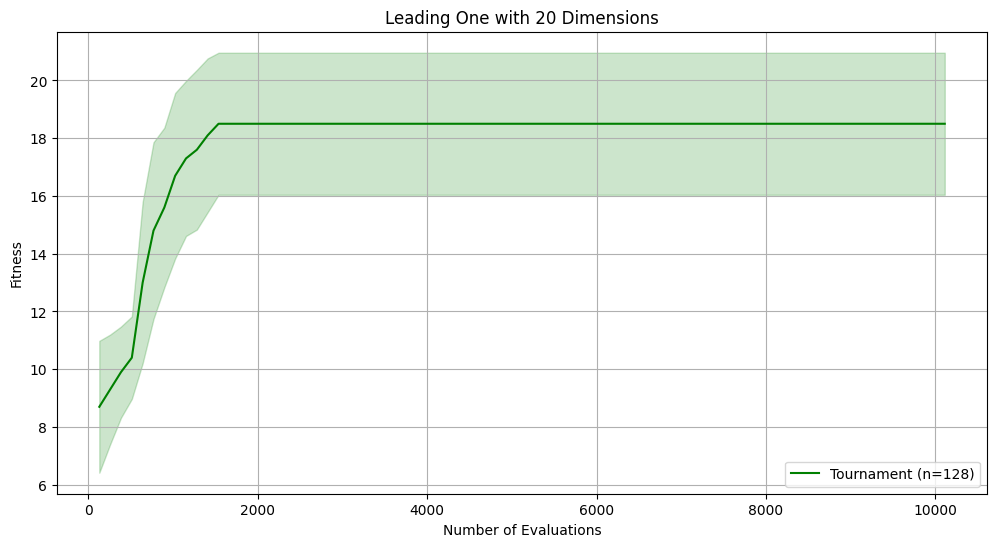

In [30]:
tournament_num_individuals = 128
tournament_evals, tournament_avg, tournament_err = run_and_plot(
    tournament_num_individuals,
    num_parameters,
    "leading_one",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

In [31]:
print("Max Avg Fitness:", np.max(tournament_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    tournament_evals[np.where(tournament_avg == np.max(tournament_avg))[0][0]],
)

Max Avg Fitness: 18.5
No. Evaluations to reach Max Avg Fitness: 1536


### 2.3.4. Comparison of the Three Selection Methods


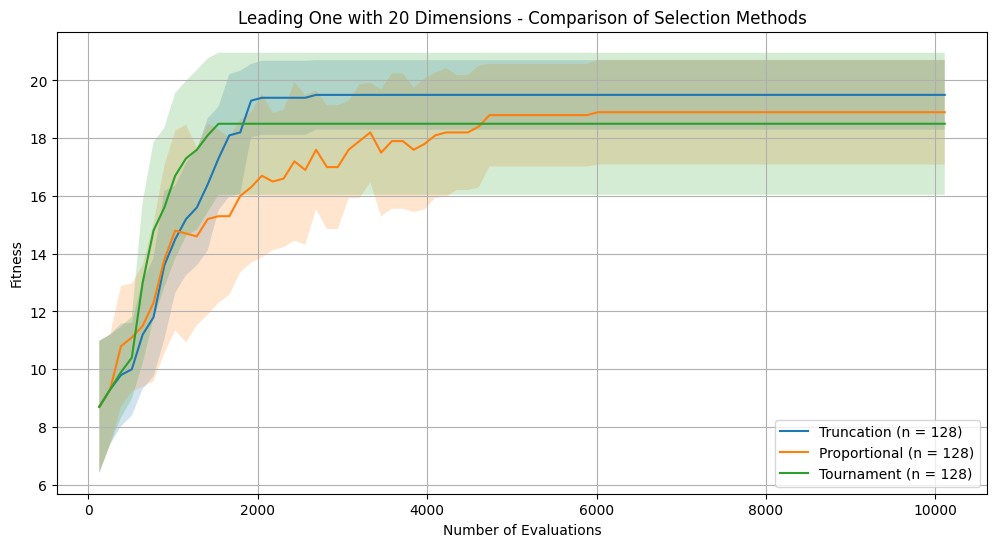

In [32]:
plt.figure(figsize=(12, 6))
plt.plot(
    truncation_evals,
    truncation_avg,
    label=f"Truncation (n = {truncation_num_individuals})",
)
plt.fill_between(
    truncation_evals,
    truncation_avg - truncation_err,
    truncation_avg + truncation_err,
    alpha=0.2,
)
plt.plot(
    proportional_evals,
    proportional_avg,
    label=f"Proportional (n = {proportional_num_individuals})",
)
plt.fill_between(
    proportional_evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(
    tournament_evals,
    tournament_avg,
    label=f"Tournament (n = {tournament_num_individuals})",
)
plt.fill_between(
    tournament_evals,
    tournament_avg - tournament_err,
    tournament_avg + tournament_err,
    alpha=0.2,
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(
    f"Leading One with {num_parameters} Dimensions - Comparison of Selection Methods"
)
plt.legend()
plt.grid()
plt.show()

In [33]:
print(f"Truncation: {truncation_avg[-1]:.2f} ± {truncation_err[-1]:.2f}")
print(f"Proportional: {proportional_avg[-1]:.2f} ± {proportional_err[-1]:.2f}")
print(f"Tournament: {tournament_avg[-1]:.2f} ± {tournament_err[-1]:.2f}")

Truncation: 19.50 ± 1.20
Proportional: 18.90 ± 1.81
Tournament: 18.50 ± 2.46


### 2.3.5. Discussion


I can conclude from the plot that the **truncation selection** method is still the best algorithm for the LeadingOne benchmark function. However the benchmark function Leading One is more difficult to optimize than One Max, therefore none of the three selection methods can achieve the highest possible avg fitness of 20.0. **The benchmark also increases the variance of the fitness across generations significantly**.

The noticeable change is now that the **tournament selection** is the worst-performing method, achieving the highest avg fitness of only 18.50 with highest variance overall. While the **proportional selection** surprisingly converges to the highest avg fitness of 18.90 with lower variance overall compared to tournament selection, makes it the second-best method for this benchmark function.


## 2.4. Experimenting with Concatenated Trap-5 Function (25 bits)


In [34]:
num_parameters = 25

### 2.4.1. With Truncation Selection


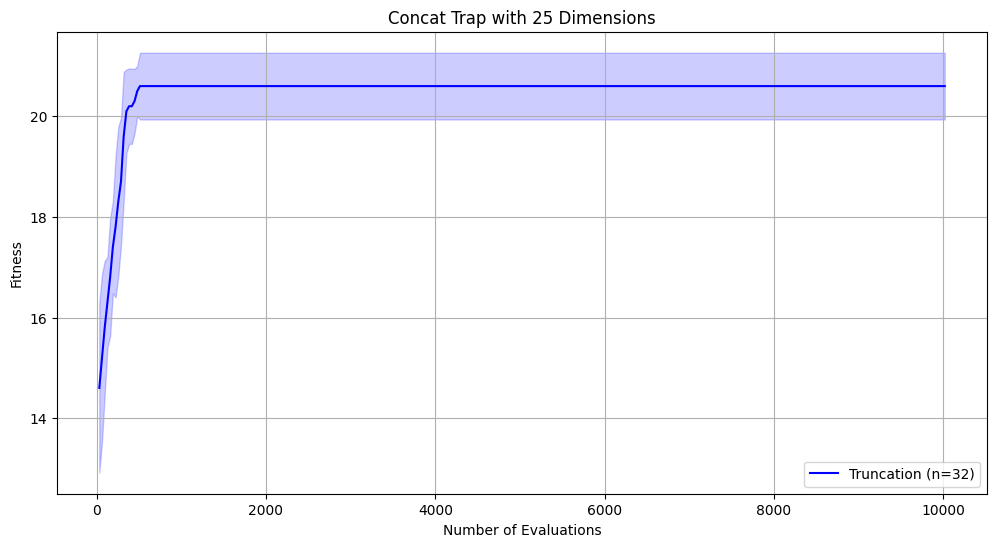

In [35]:
truncation_num_individuals = 32
truncation_evals, truncation_avg, truncation_err = run_and_plot(
    truncation_num_individuals,
    num_parameters,
    "concat_trap",
    "truncation",
    MAX_EVALUATIONS,
)

In [36]:
print("Max Avg Fitness:", np.max(truncation_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    truncation_evals[np.where(truncation_avg == np.max(truncation_avg))[0][0]],
)

Max Avg Fitness: 20.6
No. Evaluations to reach Max Avg Fitness: 512


### 2.4.2. With Proportional Selection


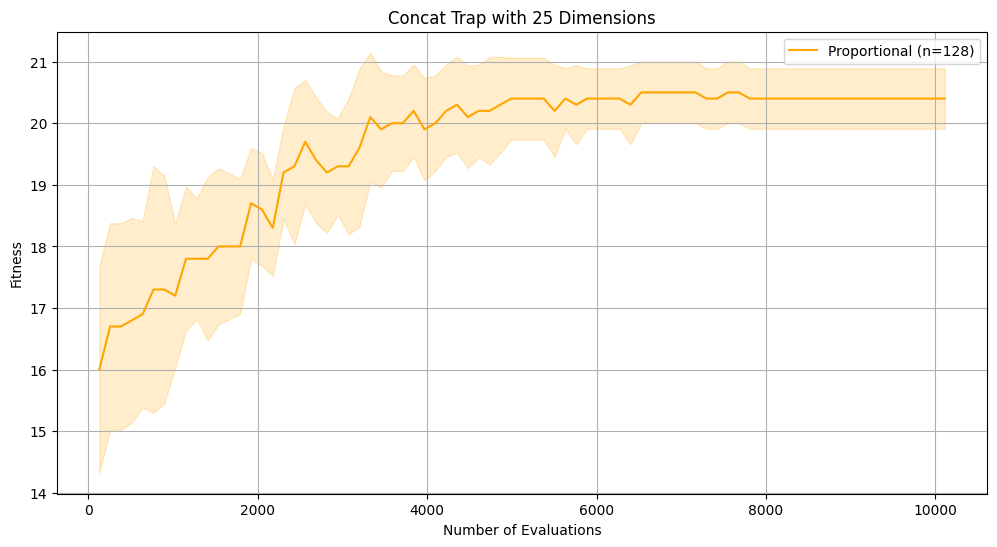

In [37]:
proportional_num_individuals = 128
proportional_evals, proportional_avg, proportional_err = run_and_plot(
    proportional_num_individuals,
    num_parameters,
    "concat_trap",
    "proportional",
    MAX_EVALUATIONS,
    "orange",
)

In [38]:
print("Max Avg Fitness:", np.max(proportional_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    proportional_evals[np.where(proportional_avg == np.max(proportional_avg))[0][0]],
)

Max Avg Fitness: 20.5
No. Evaluations to reach Max Avg Fitness: 6528


### 2.4.3. With Tournament Selection


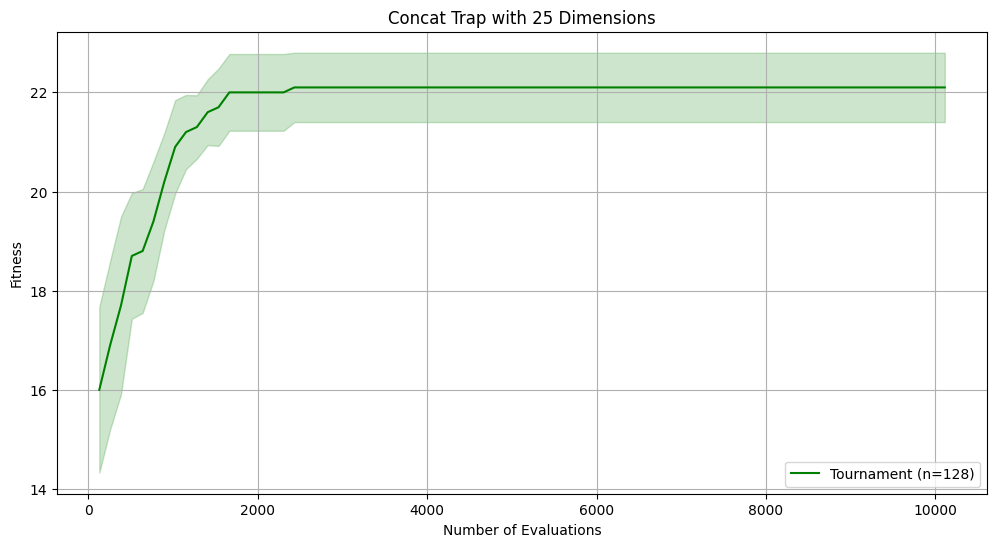

In [39]:
tournament_num_individuals = 128
tournament_evals, tournament_avg, tournament_err = run_and_plot(
    tournament_num_individuals,
    num_parameters,
    "concat_trap",
    "tournament",
    MAX_EVALUATIONS,
    "green",
)

In [40]:
print("Max Avg Fitness:", np.max(tournament_avg))
print(
    "No. Evaluations to reach Max Avg Fitness:",
    tournament_evals[np.where(tournament_avg == np.max(tournament_avg))[0][0]],
)

Max Avg Fitness: 22.1
No. Evaluations to reach Max Avg Fitness: 2432


### 2.4.4. Comparison of the Three Selection Methods


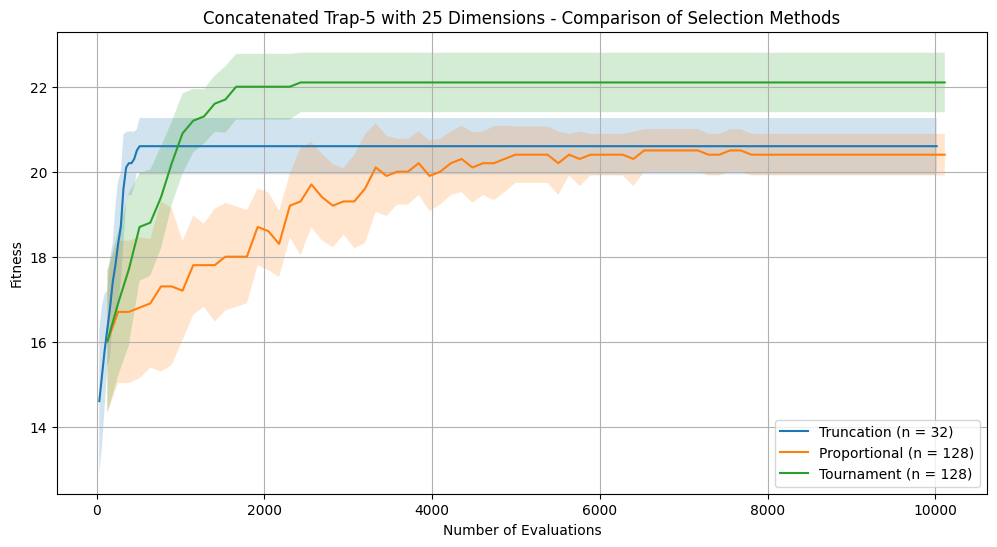

In [41]:
plt.figure(figsize=(12, 6))
plt.plot(
    truncation_evals,
    truncation_avg,
    label=f"Truncation (n = {truncation_num_individuals})",
)
plt.fill_between(
    truncation_evals,
    truncation_avg - truncation_err,
    truncation_avg + truncation_err,
    alpha=0.2,
)
plt.plot(
    proportional_evals,
    proportional_avg,
    label=f"Proportional (n = {proportional_num_individuals})",
)
plt.fill_between(
    proportional_evals,
    proportional_avg - proportional_err,
    proportional_avg + proportional_err,
    alpha=0.2,
)
plt.plot(
    tournament_evals,
    tournament_avg,
    label=f"Tournament (n = {tournament_num_individuals})",
)
plt.fill_between(
    tournament_evals,
    tournament_avg - tournament_err,
    tournament_avg + tournament_err,
    alpha=0.2,
)
plt.xlabel("Number of Evaluations")
plt.ylabel("Fitness")
plt.title(
    f"Concatenated Trap-5 with {num_parameters} Dimensions - Comparison of Selection Methods"
)
plt.legend()
plt.grid()
plt.show()

In [42]:
print(f"Truncation: {truncation_avg[-1]:.2f} ± {truncation_err[-1]:.2f}")
print(f"Proportional: {proportional_avg[-1]:.2f} ± {proportional_err[-1]:.2f}")
print(f"Tournament: {tournament_avg[-1]:.2f} ± {tournament_err[-1]:.2f}")

Truncation: 20.60 ± 0.66
Proportional: 20.40 ± 0.49
Tournament: 22.10 ± 0.70


### 2.4.5. Discussion


With the concatenated trap-5 function, the best-performing method is now **tournament selection**. It converges slower than **truncation selection** but outperforms the other two methods, achieving the highest avg fitness of 22.10. **Proportional selection** performs the worst (converging at 20.40) but it is just slightly worse than truncation selection (converging at 20.60).

Three methods are all struggling to optimize the concatenated trap-5 function (25 bits), which is a more difficult benchmark function than the previous two. However the variance of the fitness across generations is significantly reduced compared to Leading One benchmark.


# 3. Conclusion


There are no clear winners across all three benchmark functions. While **Truncation Selection** are better than the other two methods in the first two benchmark functions, it performs worse than **Tournament Selection** in the Concatenated Trap-5 benchmark. **Proportional Selection** is the overall worst-performing method across all three benchmark functions.

If I must choose an overall winner based on these specific charts, **Tournament Selection** is arguably the most robust choice. It dominated the deceptive Trap-5 function and performed exceptionally well (tied for first) on the simple One Max function. While it fell slightly behind Truncation and Proportional Selection on Leading One, its ability to avoid worst-case scenarios across varying problem types makes it highly reliable. **Truncation** is a close second, excelling in simpler, non-deceptive landscapes but faltering when faced with "traps."

**Selection Method - Performance Analysis**

- **Truncation Selection** applies very high selection pressure by strictly taking the top percentage of the population. This leads to excellent and rapid results in smooth, unimodal landscapes (One Max, Leading One). However, this greedy approach rapidly destroys genetic diversity, making it highly susceptible to getting stuck in local optima on deceptive landscapes (Trap-5).
- **Proportional Selection** clearly struggles due to a loss of **selection pressure**. As the population improves and fitness values become closer to one another, the probability of selecting the best individuals over average ones diminishes drastically. This causes the algorithm to stall, as seen vividly in the One Max graph.
- **Tournament Selection** provides an excellent balance. By adjusting the tournament size, it maintains enough selection pressure to converge quickly (seen in One Max), while still preserving enough genetic diversity to escape deceptive traps better than Truncation (seen in Trap-5).
